# Assignment 4: Classification of Student Placement using SVM, CART, KNN and Naive Bayes

**Name:** Parth Isekar  |  **PRN:** 202401080062

**Objective:** Predict whether a student gets placed (`Placed` = Yes/No) using academic, skill and background attributes, and compare four classification algorithms.

**Run instruction:** Keep `student_placement_dataset.csv` in the same folder as this notebook before running all cells.


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay)

df = pd.read_csv("student_placement_dataset.csv")
print(df.shape)
df.head()

(1200, 18)


,Student_ID,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular,Placed
0,STU1000,Male,Mechanical,85.2,75.9,7.17,2,0.0,3,1,65.0,Medium,1.8,Tier-3,Yes,7.98,No,No
1,STU1001,Male,IT,85.0,72.7,6.41,0,0.0,3,2,69.0,Low,2.5,Tier-3,No,12.46,Yes,Yes
2,STU1002,Female,Civil,79.7,85.1,7.46,1,1.0,2,0,72.0,Medium,7.3,Tier-3,Yes,5.70,No,Yes
3,STU1003,Female,Mechanical,81.6,67.0,4.51,1,1.0,0,3,63.0,Medium,20.3,Tier-2,Yes,3.68,No,No
4,STU1004,Male,Computer,70.5,78.8,8.19,0,0.0,2,0,62.0,High,3.5,Tier-1,No,18.97,Yes,Yes


## 1. Data Preprocessing

### 1.1 Inspecting the data

In [2]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs :", df['Student_ID'].duplicated().sum())
print("\nClass balance (Placed):")
print(df['Placed'].value_counts())
print("\nMissing values:")
missing = df.isna().sum()
missing[missing > 0].to_frame('missing').assign(percent=lambda t: (t['missing'] / len(df) * 100).round(1))

Duplicate rows: 0
Duplicate IDs : 0

Class balance (Placed):
Placed
No     673
Yes    527
Name: count, dtype: int64

Missing values:


,missing,percent
HSC_Percentage,29,2.4
CGPA,56,4.7
Internships,50,4.2
Aptitude_Score,81,6.8
Communication_Skill,59,4.9
Coding_Hours_Per_Week,100,8.3
City_Tier,27,2.2
Family_Income_LPA,131,10.9


The dataset has 1,200 students and 18 columns. Eight columns contain missing values (2% to 11% of rows), there are no duplicates, and the classes are reasonably balanced (56% not placed, 44% placed), so plain accuracy is a usable metric alongside the others.

### 1.2 Preprocessing plan

| Step | Columns | Method | Reason |
|---|---|---|---|
| Drop identifier | `Student_ID` | Removed | Unique per row, carries no information |
| Missing numeric values | CGPA, HSC %, Internships, Aptitude, Coding hours, Family income | Median imputation | Robust to outliers (e.g. coding hours up to 36.5, income up to 40.1 LPA) |
| Missing categorical values | `Communication_Skill`, `City_Tier` | Most-frequent (mode) imputation | Standard for categories |
| Ordered categories | `Communication_Skill` (Low < Medium < High), `City_Tier` (Tier-3 < Tier-2 < Tier-1) | Ordinal encoding | Preserves the natural order |
| Unordered categories | `Gender`, `Branch`, `Hostel_Resident`, `Extracurricular` | One-hot encoding (binary columns as a single 0/1 column) | No order between values |
| Scaling | All numeric and ordinal features | Standardisation (zero mean, unit variance) | SVM and KNN are distance-based and sensitive to feature scale |
| Target | `Placed` | Yes → 1, No → 0 | Binary label |

The data is split **before** fitting any imputer or scaler. All preprocessing is wrapped in a `Pipeline`, so statistics are learned from the training data only and no test information leaks into training.

In [3]:
y = (df['Placed'] == 'Yes').astype(int)
X = df.drop(columns=['Student_ID', 'Placed'])

numeric_cols = X.select_dtypes('number').columns.tolist()
ordinal_cols = ['Communication_Skill', 'City_Tier']
nominal_cols = ['Gender', 'Branch', 'Hostel_Resident', 'Extracurricular']

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale',  StandardScaler())]), numeric_cols),
    ('ord', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OrdinalEncoder(categories=[['Low', 'Medium', 'High'],
                                                            ['Tier-3', 'Tier-2', 'Tier-1']])),
                      ('scale',  StandardScaler())]), ordinal_cols),
    ('nom', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))]), nominal_cols),
])

# 80/20 stratified split keeps the Placed ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Xt = preprocess.fit_transform(X_train)
print("Features after encoding:", Xt.shape[1], "| missing values left:", int(np.isnan(Xt).sum()))

Train: (960, 16)  Test: (240, 16)
Features after encoding: 21 | missing values left: 0


## 2. Model Implementation

Four classifiers were trained using the same preprocessing pipeline. The settings below were used for this dataset. The test set was kept separate for final evaluation.

| Model | Settings |
|---|---|
| SVM | Linear kernel, C = 0.1, probability estimates enabled for log loss |
| Decision Tree (CART) | Gini criterion, max_depth = 3, min_samples_leaf = 10 |
| KNN | 21 neighbours, uniform weights |
| Naive Bayes | GaussianNB with default settings |

Each model is placed in a Pipeline with a fresh copy of the preprocessing steps. This ensures that imputation, encoding and scaling are fitted on the training data.


In [8]:
models = {
    "SVM": SVC(C=0.1, kernel="linear", probability=True, random_state=42),
    "CART": DecisionTreeClassifier(criterion="gini", max_depth=3,
                                   min_samples_leaf=10, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=21, weights="uniform"),
    "Naive Bayes": GaussianNB()
}

fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", clone(preprocess)), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    print(name, "trained")


SVM trained
CART trained
KNN trained
Naive Bayes trained


## 3. Training and Evaluation

**Metrics used** (positive class = Placed):

- **Accuracy**: share of all predictions that are correct.
- **Precision**: of the students predicted as placed, the fraction actually placed (cost of false positives).
- **Recall**: of the students actually placed, the fraction the model found (cost of false negatives).
- **F1-score**: harmonic mean of precision and recall; a single balanced score.
- **Loss (log loss)**: penalises confident wrong probability estimates; lower is better. Unlike the other metrics it measures the quality of predicted probabilities, not just the final label.

Train accuracy is reported next to test accuracy to check for overfitting.

In [5]:
rows, preds = [], {}
for name, m in fitted.items():
    y_pred, y_prob = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    preds[name] = y_pred
    rows.append({'Model': name,
                 'Train Acc': accuracy_score(y_train, m.predict(X_train)),
                 'Accuracy':  accuracy_score(y_test, y_pred),
                 'Precision': precision_score(y_test, y_pred),
                 'Recall':    recall_score(y_test, y_pred),
                 'F1-score':  f1_score(y_test, y_pred),
                 'Log Loss':  log_loss(y_test, y_prob)})

results = pd.DataFrame(rows).set_index('Model').round(3)
results

,Train Acc,Accuracy,Precision,Recall,F1-score,Log Loss
Model,,,,,,
SVM,0.788,0.767,0.758,0.686,0.720,0.452
CART,0.730,0.738,0.769,0.571,0.656,0.552
KNN,0.767,0.733,0.711,0.657,0.683,0.510
Naive Bayes,0.754,0.742,0.705,0.705,0.705,0.548


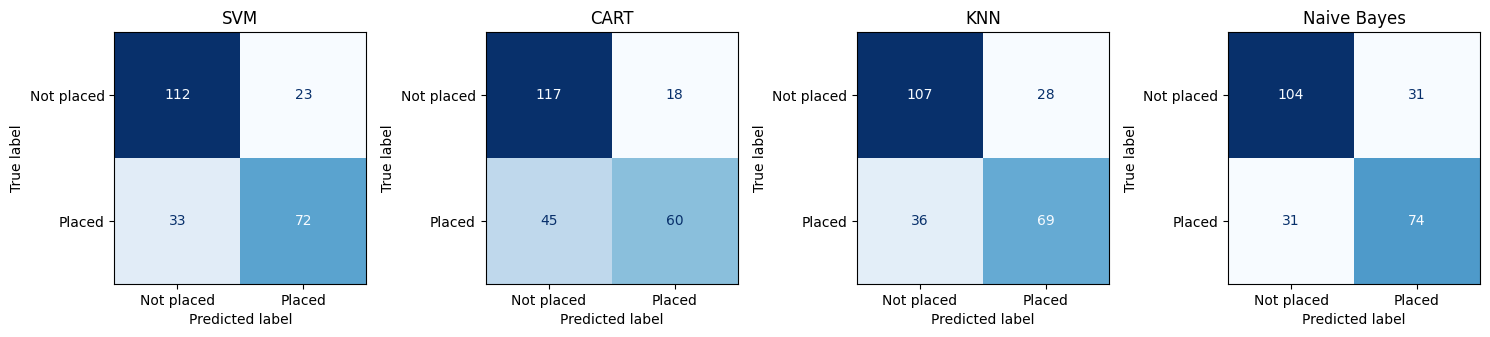

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=['Not placed', 'Placed']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 4. Comparative Analysis

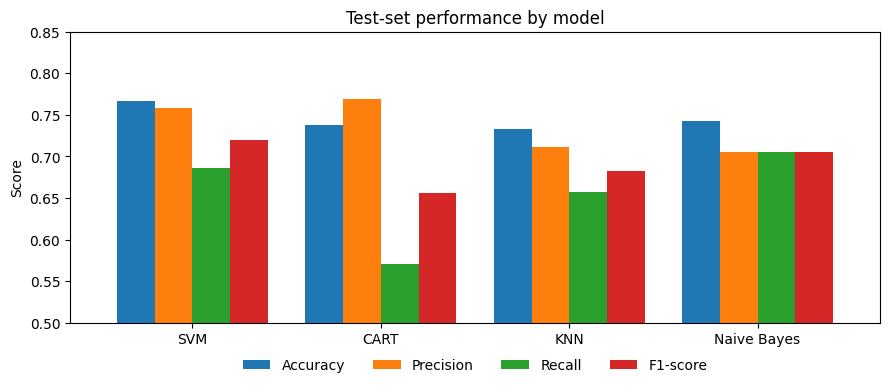

In [7]:
ax = results[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(
    kind='bar', figsize=(9, 4), rot=0, ylim=(0.5, 0.85), width=0.8)
ax.set_title("Test-set performance by model"); ax.set_ylabel("Score"); ax.set_xlabel("")
ax.legend(loc='upper center', ncol=4, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout(); plt.show()

**Observations**

- **SVM** has the highest test accuracy (0.767) and F1-score (0.720), and the lowest log loss (0.452). The selected model uses a linear kernel with C = 0.1.
- **Decision Tree (CART)** has the highest precision (0.769), but the lowest recall (0.571). It identifies fewer of the students who are actually placed.
- **KNN** has the lowest test accuracy (0.733). Its performance may be affected by distance calculations across 21 encoded features.
- **Naive Bayes** has the highest recall (0.705), meaning it identifies the largest share of students who are actually placed. Its log loss is 0.548.
- Test accuracies range from 0.733 to 0.767. The differences are modest on a test set of 240 students, so the ranking should be treated as specific to this split.
- Train and test accuracies are close for all four models; this split does not show a large train-test accuracy gap.


## 5. Conclusion

The four classifiers were trained and evaluated on the student placement dataset. SVM achieved the highest test accuracy (0.767) and F1-score (0.720), together with the lowest log loss (0.452). Naive Bayes achieved the highest recall (0.705), while the CART decision tree achieved the highest precision (0.769). KNN had the lowest test accuracy (0.733).

SVM is the strongest overall choice for this train-test split. CART is useful when decision rules need to be interpreted. Naive Bayes is a simple option when identifying as many placed students as possible is important. KNN is straightforward but may be less suitable when the feature space contains many encoded variables.
